In [16]:
file_path = "Documents/ecommerce_churn_rate_raw.csv"
df= pd.read_csv(file_path)
print (df.columns)

Index(['churn_id', 'customer_id', 'customer_segment', 'customer_country',
       'customer_city', 'is_churned', 'churn_flag', 'churn_date',
       'days_since_churn', 'churn_reason', 'churn_category',
       'churn_risk_score', 'churn_probability', 'subscription_type',
       'customer_age_months', 'total_spend_usd', 'avg_order_value_usd',
       'num_purchases', 'satisfaction_score', 'satisfaction_level',
       'support_tickets', 'returns_count', 'days_since_last_purchase',
       'customer_lifetime_value_usd', 'engagement_level', 'prevention_method',
       'support_interactions', 'last_support_channel', 'feedback_score',
       'loyalty_score', 'marketing_emails_sent', 'marketing_emails_opened',
       'marketing_emails_clicked', 'marketing_conversions',
       'social_media_engagement', 'referral_count', 'is_high_risk_customer',
       'predicted_churn', 'customer_retention_cost_usd',
       'recovery_revenue_usd', 'dataset_year', 'churn_rate_indicator',
       'customer_value_cat

--- AVERAGE FRICTION METRICS ---
            support_tickets  returns_count  satisfaction_score
is_churned                                                    
No                 8.775274       4.374075            3.262251
Yes               10.518741       4.802276            2.564988


--- CORRELATION WITH CHURN ---
is_churned_numeric    1.000000
support_tickets       0.150647
returns_count         0.074353
satisfaction_score   -0.243701
Name: is_churned_numeric, dtype: float64


Generating Seaborn Visualizations...


C:\Users\user\AppData\Local\Temp\ipykernel_7528\3612796727.py:31: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='is_churned', y='support_tickets', data=df, palette='Blues_d', ci=None)
C:\Users\user\AppData\Local\Temp\ipykernel_7528\3612796727.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='is_churned', y='support_tickets', data=df, palette='Blues_d', ci=None)


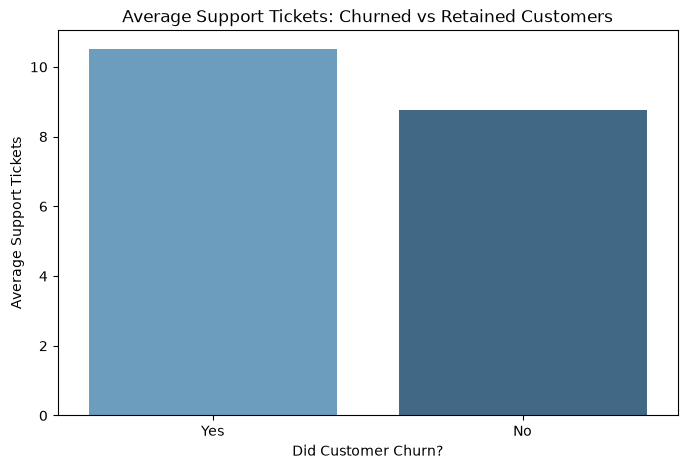

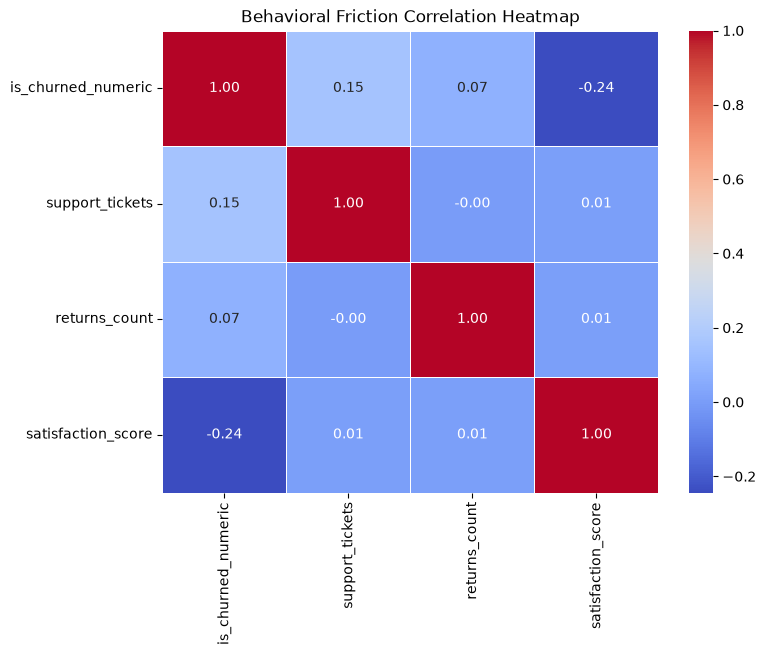

In [11]:
#Do higher support ticket counts or product returns correlate with churn?
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load your dataset
file_path = "Documents/ecommerce_churn_rate_raw.csv"
df= pd.read_csv(file_path)

# 2. Convert 'is_churned' (Yes/No) into numbers (1/0) for correlation math
df['is_churned_numeric'] = df['is_churned'].apply(lambda x: 1 if x == 'Yes' else 0)

# 3. Print out the numerical averages using Pandas
friction_summary = df.groupby('is_churned')[['support_tickets', 'returns_count', 'satisfaction_score']].mean()
print("--- AVERAGE FRICTION METRICS ---")
print(friction_summary)

print("\n" + "="*50 + "\n")

# 4. Calculate the Correlation Matrix
cols_to_check = ['is_churned_numeric', 'support_tickets', 'returns_count', 'satisfaction_score']
correlation_table = df[cols_to_check].corr()
print("--- CORRELATION WITH CHURN ---")
print(correlation_table['is_churned_numeric'].sort_values(ascending=False))

print("\n" + "="*50 + "\n")
print("Generating Seaborn Visualizations...")

# 5. VISUAL 1: Seaborn Barplot (Support Tickets vs Churn)
plt.figure(figsize=(8, 5))
sns.barplot(x='is_churned', y='support_tickets', data=df, palette='Blues_d', ci=None)
plt.title('Average Support Tickets: Churned vs Retained Customers')
plt.xlabel('Did Customer Churn?')
plt.ylabel('Average Support Tickets')
plt.show()

# 6. VISUAL 2: Seaborn Heatmap (Correlation Matrix)
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_table, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Behavioral Friction Correlation Heatmap')
plt.show()


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# load the data set
file_path = "Documents/ecommerce_churn_rate_raw.csv"
df= pd.read_csv(file_path)

# convert churn to numeric
df['is_churned_numeric'] = df['is_churned'].apply(lambda x: 1 if x == 'Yes' else 0)

# 1. Define our Features (X) and Target (y)
# We will use support tickets, returns, and satisfaction score to predict churn
X = df[['support_tickets', 'returns_count', 'satisfaction_score']]
y = df['is_churned_numeric'] # 1 if churned, 0 if retained

# 2. Split data into Training set (80%) and Testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# 4. Make predictions on our test data
y_pred = model.predict(X_test)

# 5. Evaluate the Model Performance
accuracy = accuracy_score(y_test, y_pred)
print(f"--- MODEL ACCURACY: {accuracy * 100:.2f}% ---\n")

print("--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred))

print("--- CONFUSION MATRIX ---")
print(confusion_matrix(y_test, y_pred))

--- MODEL ACCURACY: 63.01% ---

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0       0.62      0.65      0.64      4193
           1       0.64      0.61      0.62      4207

    accuracy                           0.63      8400
   macro avg       0.63      0.63      0.63      8400
weighted avg       0.63      0.63      0.63      8400

--- CONFUSION MATRIX ---
[[2726 1467]
 [1640 2567]]


--- Q6: SATISFACTION SCORE SUMMARY ---
            satisfaction_score
is_churned                    
No                    3.262251
Yes                   2.564988


C:\Users\user\AppData\Local\Temp\ipykernel_7528\2751061524.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='is_churned', y='satisfaction_score', data=df, palette='Blues_d', errorbar=None)


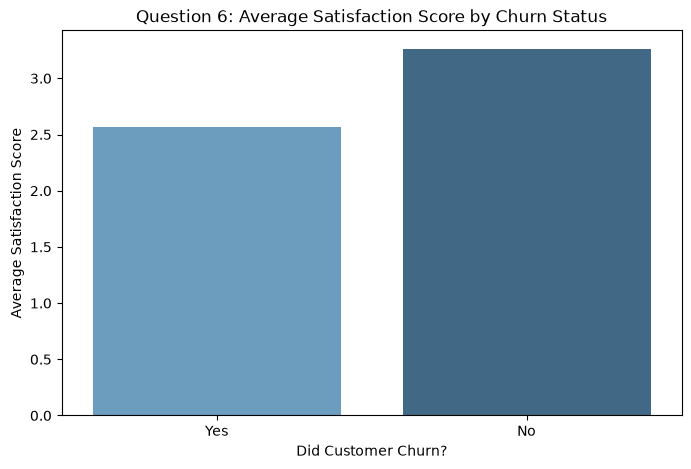

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
file_path = "Documents/ecommerce_churn_rate_raw.csv"
df = pd.read_csv(file_path)

# Convert churn to numeric for calculations
df['is_churned_numeric'] = df['is_churned'].apply(lambda x: 1 if x == 'Yes' else 0)

# Summary and Plot
print("--- Q6: SATISFACTION SCORE SUMMARY ---")
print(df.groupby('is_churned')[['satisfaction_score']].mean())

plt.figure(figsize=(8, 5))
sns.barplot(x='is_churned', y='satisfaction_score', data=df, palette='Blues_d', errorbar=None)
plt.title('Question 6: Average Satisfaction Score by Churn Status')
plt.xlabel('Did Customer Churn?')
plt.ylabel('Average Satisfaction Score')
plt.show()

--- Q8: ENGAGEMENT & LOYALTY SUMMARY ---
            loyalty_score
is_churned               
No              49.864813
Yes             50.348542


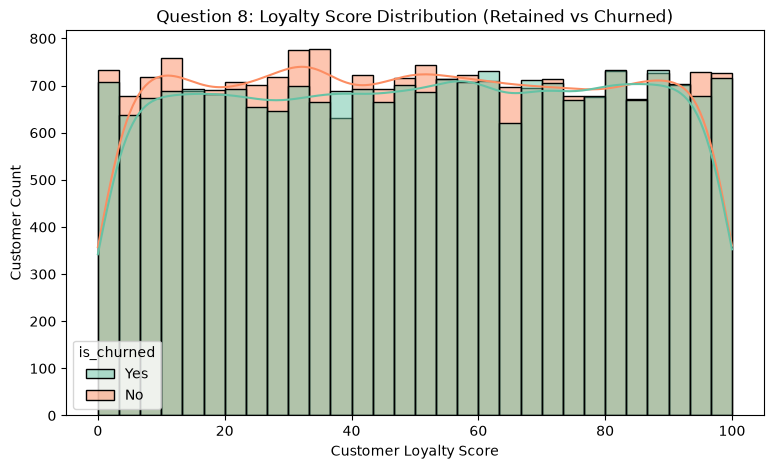

C:\Users\user\AppData\Local\Temp\ipykernel_7528\1642642815.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_churned', y='loyalty_score', data=df, palette='Set2')


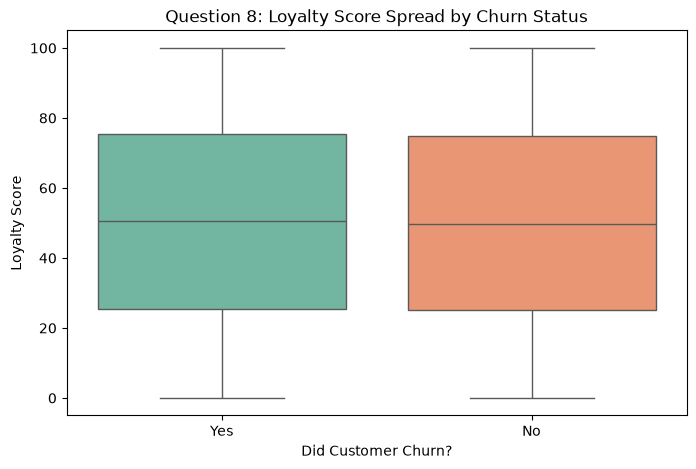

In [13]:
print("--- Q8: ENGAGEMENT & LOYALTY SUMMARY ---")
print(df.groupby('is_churned')[['loyalty_score']].mean())

# Distribution plot (KDE / Histplot) for Loyalty Score
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='loyalty_score', hue='is_churned', kde=True, palette='Set2', bins=30)
plt.title('Question 8: Loyalty Score Distribution (Retained vs Churned)')
plt.xlabel('Customer Loyalty Score')
plt.ylabel('Customer Count')
plt.show()

# Boxplot companion to show the spread
plt.figure(figsize=(8, 5))
sns.boxplot(x='is_churned', y='loyalty_score', data=df, palette='Set2')
plt.title('Question 8: Loyalty Score Spread by Churn Status')
plt.xlabel('Did Customer Churn?')
plt.ylabel('Loyalty Score')
plt.show()